<a href="https://colab.research.google.com/github/Mutaqie/Latihan-Machine-Learning/blob/main/Pertemuan%202/Latihan2_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, learning_curve
from sklearn.tree import DecisionTreeClassifier

In [3]:
# Membaca dataset
data = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Persiapan dan pembersihan data
data = data.drop(columns=["customerID"])

# TotalCharges masih berupa teks pada sebagian data
data["TotalCharges"] = pd.to_numeric(
    data["TotalCharges"], errors="coerce"
)
data["TotalCharges"] = data["TotalCharges"].fillna(
    data["TotalCharges"].median()
)

# Mengubah variabel kategorikal menjadi numerik
features = pd.get_dummies(
    data.drop(columns=["Churn"]),
    drop_first=True
)

target = data["Churn"].replace({
    "No": 0,
    "Yes": 1
}).astype(int)

print("Jumlah data :", len(data))
print("Distribusi Churn:")
print(target.value_counts().sort_index())

Jumlah data : 7043
Distribusi Churn:
Churn
0    5174
1    1869
Name: count, dtype: int64


/tmp/ipykernel_728/985193393.py:21: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  target = data["Churn"].replace({


In [6]:
# Membagi dataset menjadi training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    features,
    target,
    test_size=0.20,
    random_state=42,
    stratify=target
)

print("\nUkuran training :", X_train.shape)
print("Ukuran testing  :", X_test.shape)




Ukuran training : (5634, 30)
Ukuran testing  : (1409, 30)



1 -> Training: 0.7350 | Validasi: 0.7286

4 -> Training: 0.7971 | Validasi: 0.7827

Tanpa batas -> Training: 0.9984 | Validasi: 0.7300


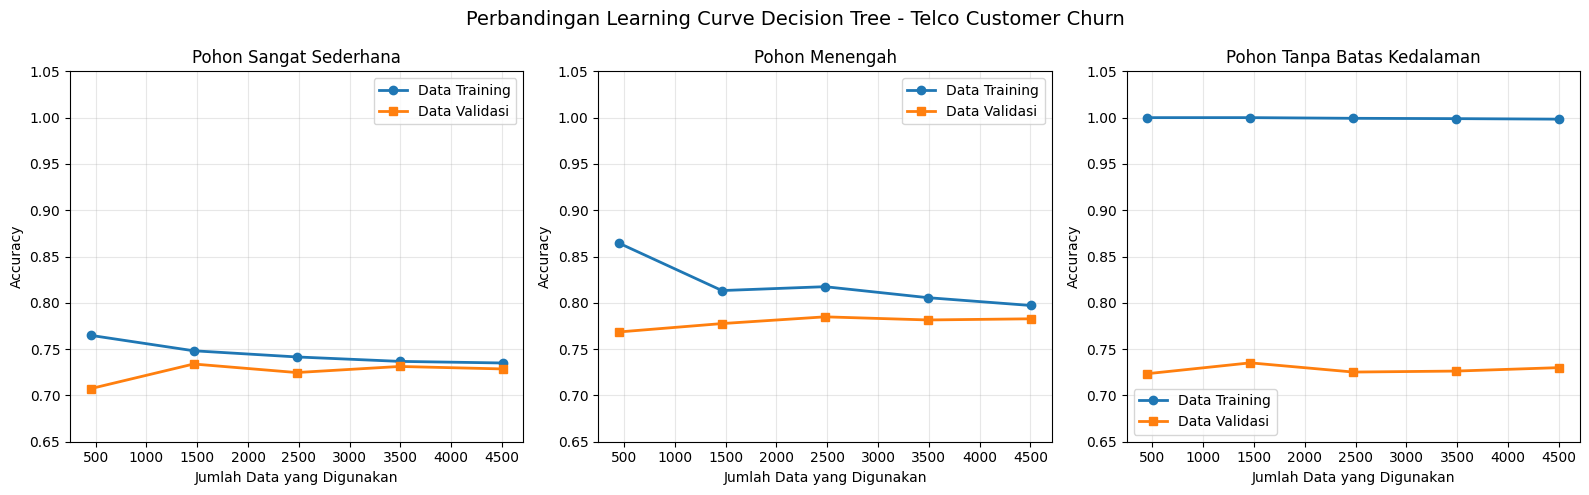

In [7]:
# Tiga tingkat kompleksitas Decision Tree
model_depths = [1, 4, None]
model_names = [
    "Pohon Sangat Sederhana",
    "Pohon Menengah",
    "Pohon Tanpa Batas Kedalaman"
]

# Lima ukuran data training untuk learning curve
sample_portions = np.linspace(0.1, 1.0, 5)

plt.figure(figsize=(16, 5))

for nomor, (kedalaman, nama) in enumerate(
    zip(model_depths, model_names), start=1
):

    tree = DecisionTreeClassifier(
        max_depth=kedalaman,
        random_state=42
    )

    ukuran, skor_train, skor_validasi = learning_curve(
        estimator=tree,
        X=X_train,
        y=y_train,
        cv=5,
        train_sizes=sample_portions,
        scoring="accuracy",
        n_jobs=-1
    )

    rata_train = skor_train.mean(axis=1)
    rata_validasi = skor_validasi.mean(axis=1)

    # Grafik learning curve
    ax = plt.subplot(1, 3, nomor)

    ax.plot(
        ukuran,
        rata_train,
        marker="o",
        linewidth=2,
        label="Data Training"
    )

    ax.plot(
        ukuran,
        rata_validasi,
        marker="s",
        linewidth=2,
        label="Data Validasi"
    )

    ax.set_title(nama)
    ax.set_xlabel("Jumlah Data yang Digunakan")
    ax.set_ylabel("Accuracy")
    ax.set_ylim(0.65, 1.05)
    ax.grid(alpha=0.3)
    ax.legend()

    # Menampilkan nilai terakhir
    print(
        f"\n{kedalaman if kedalaman is not None else 'Tanpa batas'}"
        f" -> Training: {rata_train[-1]:.4f}"
        f" | Validasi: {rata_validasi[-1]:.4f}"
    )

plt.suptitle(
    "Perbandingan Learning Curve Decision Tree - Telco Customer Churn",
    fontsize=14
)
plt.tight_layout()
plt.show()


In [8]:
# Diagnosis hasil
print("\n" + "=" * 60)
print("HASIL DIAGNOSIS")
print("=" * 60)

print("""
Depth 1:
Model cenderung UNDERFITTING karena struktur pohon terlalu
sederhana sehingga pola pada data belum dapat dipelajari
secara optimal.

Depth 4:
Model menunjukkan kondisi yang relatif GOOD FIT. Nilai training
dan validasi cukup berdekatan sehingga kemampuan generalisasi
lebih seimbang.

Depth None:
Model mengalami OVERFITTING. Nilai training sangat tinggi,
sedangkan nilai validasi jauh lebih rendah. Hal ini menunjukkan
pohon terlalu kompleks dan banyak mempelajari pola khusus
pada data training.
""")


HASIL DIAGNOSIS

Depth 1:
Model cenderung UNDERFITTING karena struktur pohon terlalu
sederhana sehingga pola pada data belum dapat dipelajari
secara optimal.

Depth 4:
Model menunjukkan kondisi yang relatif GOOD FIT. Nilai training
dan validasi cukup berdekatan sehingga kemampuan generalisasi
lebih seimbang.

Depth None:
Model mengalami OVERFITTING. Nilai training sangat tinggi,
sedangkan nilai validasi jauh lebih rendah. Hal ini menunjukkan
pohon terlalu kompleks dan banyak mempelajari pola khusus
pada data training.

